In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
import json

# I use the same project directory as my previous notebooks.
PROJECT_ROOT = Path(
    r"G:\My Drive\Projects\Large projects\2026TexasEnergyFootprint"
)

MOSAIC = (
    PROJECT_ROOT
    / "07_Visualization"
    / "03_Texas_Energy_Land_Mosaic"
)

# I keep the original mosaic datasets unchanged.
source_files = {
    "Hexagon grid": "Texas_10sqmi_Hex_Grid.parquet",
    "Wells": "Texas_Wells_Hex_Final_Central.parquet",
    "Pipelines": "Texas_Pipelines_Hex_Final_Revised.parquet",
    "Solar": "Texas_Solar_Hex_Summary.parquet",
    "Wind": "Texas_Wind_Hex_Final_Revised.parquet",
    "Battery": "Texas_Battery_Hex_Final_Central.parquet"
}

# I check every required source before loading large spatial files.
source_check = pd.DataFrame([
    {
        "dataset": name,
        "filename": filename,
        "exists": (MOSAIC / filename).is_file()
    }
    for name, filename in source_files.items()
])

display(source_check)

assert PROJECT_ROOT.is_dir(), "Project directory not found."
assert MOSAIC.is_dir(), "Mosaic directory not found."
assert source_check["exists"].all(), (
    "One or more source files are missing. "
    "Check the table before continuing."
)

# I create a separate folder for the rebuilt final outputs.
OUTPUT = MOSAIC / "Final_Rebuilt"
OUTPUT.mkdir(parents=True, exist_ok=True)

print("All six source files found.")
print("Output folder:", OUTPUT)

,dataset,filename,exists
0,Hexagon grid,Texas_10sqmi_Hex_Grid.parquet,True
1,Wells,Texas_Wells_Hex_Final_Central.parquet,True
2,Pipelines,Texas_Pipelines_Hex_Final_Revised.parquet,True
3,Solar,Texas_Solar_Hex_Summary.parquet,True
4,Wind,Texas_Wind_Hex_Final_Revised.parquet,True
5,Battery,Texas_Battery_Hex_Final_Central.parquet,True


All six source files found.
Output folder: G:\My Drive\Projects\Large projects\2026TexasEnergyFootprint\07_Visualization\03_Texas_Energy_Land_Mosaic\Final_Rebuilt


In [3]:
# I reconstruct my final eligible pipeline centerlines from saved source files.
# I apply the same eligibility and ROW assumptions as my pipeline notebook.
# I do not rerun the county spatial union.

import geopandas as gpd
import pandas as pd
import numpy as np

pipeline_pieces_path = (
    PROJECT_ROOT / "05_Optimized_Data" / "GeoParquet"
    / "Texas_Pipeline_County_Pieces_All_Statuses.parquet"
)

pipeline_source_path = (
    PROJECT_ROOT / "03_Cleaned_Data"
    / "Texas_Pipelines_All_Statuses.gpkg"
)

# I load only the attributes needed to reconstruct eligibility.
pieces = pd.read_parquet(
    pipeline_pieces_path,
    columns=[
        "TPMS_ID", "status_code",
        "system_code", "CMDTY_DESC"
    ]
).drop_duplicates()

# I retain in-service pipelines.
pieces = pieces.loc[
    pieces["status_code"].astype("string").str.strip().str.upper().eq("I")
].copy()

system = pieces["system_code"].astype("string").str.strip().str.upper()
commodity = pieces["CMDTY_DESC"].astype("string").str.strip().str.upper()

# I reproduce my final Include, Review, and Exclude classifications.
confirmed = (
    (
        system.isin(["G", "T", "L", "O"])
        & commodity.isin([
            "NATURAL GAS", "NATURAL GAS FWS",
            "CRUDE OIL", "CRUDE FWS"
        ])
    )
    | (
        system.eq("P")
        & commodity.eq("REFINED LIQUID PRODUCT")
    )
)

review = (
    system.eq("Q")
    | (system.eq("T") & commodity.eq("OTHER GAS"))
)

excluded = (
    system.isin(["A", "C", "K", "Z"])
    | commodity.eq("HYDROGEN")
)

pieces["eligibility"] = np.select(
    [excluded, confirmed, review],
    ["Exclude", "Include", "Review"],
    default="Review"
)

eligible = pieces.loc[
    pieces["eligibility"].isin(["Include", "Review"])
].copy()

eligible["row_width_ft"] = np.where(
    system.loc[eligible.index].eq("T"),
    50.0,
    25.0
)

eligible_lookup = eligible[
    ["TPMS_ID", "row_width_ft"]
].drop_duplicates()

assert eligible_lookup["TPMS_ID"].is_unique
assert eligible_lookup["TPMS_ID"].nunique() == 428599

# I retrieve the original centerlines for the same eligible source IDs.
original = gpd.read_file(
    pipeline_source_path,
    layer="texas_pipelines",
    columns=["TPMS_ID"],
    engine="pyogrio"
)

original_eligible = original.loc[
    original["TPMS_ID"].isin(eligible_lookup["TPMS_ID"])
].copy()

original_eligible = original_eligible.merge(
    eligible_lookup,
    on="TPMS_ID",
    how="left",
    validate="many_to_one"
).to_crs("EPSG:3083")

assert len(original_eligible) == 435186
assert original_eligible["row_width_ft"].notna().all()

print("Eligible pipeline features:", f"{len(original_eligible):,}")
print("Unique source IDs:", f"{original_eligible['TPMS_ID'].nunique():,}")
print("CRS:", original_eligible.crs)
print("Final ROW widths:", sorted(original_eligible["row_width_ft"].unique()))

Eligible pipeline features: 435,186
Unique source IDs: 428,599
CRS: EPSG:3083
Final ROW widths: [np.float64(25.0), np.float64(50.0)]


In [4]:
# I reproject my eligible pipeline geometries in smaller batches.
# I avoid processing millions of coordinates simultaneously.
# I preserve my existing eligibility decisions and ROW widths.

import geopandas as gpd
import gc

BATCH_SIZE = 5000
projected_parts = []

# I use the existing source geometries without repeating the file loading.
original_eligible = original.loc[
    original["TPMS_ID"].isin(eligible_lookup["TPMS_ID"])
].copy()

original_eligible = original_eligible.merge(
    eligible_lookup,
    on="TPMS_ID",
    how="left",
    validate="many_to_one"
)

print("Eligible features:", f"{len(original_eligible):,}")
print("Original CRS:", original_eligible.crs)

for start in range(0, len(original_eligible), BATCH_SIZE):

    # I transform a small set of geometries at a time.
    part = original_eligible.iloc[
        start:start + BATCH_SIZE
    ].to_crs("EPSG:3083")

    projected_parts.append(part)

    if (start // BATCH_SIZE + 1) % 10 == 0:
        print(
            f"Projected {min(start + BATCH_SIZE, len(original_eligible)):,} "
            f"of {len(original_eligible):,} features"
        )

# I combine the projected batches after their coordinate transformations.
original_eligible = gpd.GeoDataFrame(
    pd.concat(projected_parts, ignore_index=True),
    geometry="geometry",
    crs="EPSG:3083"
)

del projected_parts, original
gc.collect()

assert len(original_eligible) == 435186
assert original_eligible["row_width_ft"].notna().all()

print("\nProjection completed.")
print("Features:", f"{len(original_eligible):,}")
print("CRS:", original_eligible.crs)

Eligible features: 435,186
Original CRS: EPSG:4326
Projected 50,000 of 435,186 features
Projected 100,000 of 435,186 features
Projected 150,000 of 435,186 features
Projected 200,000 of 435,186 features
Projected 250,000 of 435,186 features
Projected 300,000 of 435,186 features
Projected 350,000 of 435,186 features
Projected 400,000 of 435,186 features

Projection completed.
Features: 435,186
CRS: EPSG:3083


In [6]:
from pathlib import Path

# I define the output folder using my existing project root.
FOOTPRINT = PROJECT_ROOT / "06_Energy_Footprint_Analysis"

# I save my projected eligible pipeline centerlines.
pipeline_source_out = (
    FOOTPRINT / "Pipelines" / "Pipeline_Unique_ROW"
    / "pipeline_eligible_centerlines.parquet"
)

pipeline_source_out.parent.mkdir(parents=True, exist_ok=True)

original_eligible[
    ["TPMS_ID", "row_width_ft", "geometry"]
].to_parquet(pipeline_source_out, index=False)

# I confirm that the file was saved successfully.
assert pipeline_source_out.exists()

print("Saved:", pipeline_source_out)
print("Pipeline features:", f"{len(original_eligible):,}")

Saved: G:\My Drive\Projects\Large projects\2026TexasEnergyFootprint\06_Energy_Footprint_Analysis\Pipelines\Pipeline_Unique_ROW\pipeline_eligible_centerlines.parquet
Pipeline features: 435,186


In [7]:
old_pipeline_hex_path = (
    OUTPUT / "Texas_Pipelines_Hex_Final_Rebuilt.parquet"
)

pipeline_source_path = (
    PROJECT_ROOT / "06_Energy_Footprint_Analysis"
    / "Pipelines" / "Pipeline_Unique_ROW"
    / "pipeline_eligible_centerlines.parquet"
)

# I inspect the old gross-acreage hexagon results.
pipeline_hex_old = pd.read_parquet(old_pipeline_hex_path)

print(
    "Old hexagon pipeline acreage:",
    f"{pipeline_hex_old['pipeline_acres'].sum():,.2f}"
)

# I confirm that my projected eligible centerlines were saved.
assert pipeline_source_path.exists(), "Eligible centerlines file is missing."

print("Eligible centerlines file:", pipeline_source_path)
print("Final statewide unique ROW acreage: 984,144.19")
print("Ready to calculate unique ROW acreage by hexagon.")

Old hexagon pipeline acreage: 1,100,025.28
Eligible centerlines file: G:\My Drive\Projects\Large projects\2026TexasEnergyFootprint\06_Energy_Footprint_Analysis\Pipelines\Pipeline_Unique_ROW\pipeline_eligible_centerlines.parquet
Final statewide unique ROW acreage: 984,144.19
Ready to calculate unique ROW acreage by hexagon.


In [8]:
# I compare my existing gross pipeline acreage with the
# validated statewide unique ROW acreage.

pipeline_hex_old = pd.read_parquet(
    OUTPUT / "Texas_Pipelines_Hex_Final_Rebuilt.parquet"
)

pipeline_source_path = (
    PROJECT_ROOT / "06_Energy_Footprint_Analysis"
    / "Pipelines" / "Pipeline_Unique_ROW"
    / "pipeline_eligible_centerlines.parquet"
)

assert pipeline_source_path.exists()

print(
    "Existing pipeline hexagon acreage:",
    f"{pipeline_hex_old['pipeline_acres'].sum():,.2f}"
)

print("Validated unique pipeline ROW acreage: 984,144.19")
print("Saved eligible centerlines: Found")

Existing pipeline hexagon acreage: 1,100,025.28
Validated unique pipeline ROW acreage: 984,144.19
Saved eligible centerlines: Found


In [9]:
# I load the existing 10-square-mile hexagon grid used in my analysis.

grid_path = MOSAIC / "Texas_10sqmi_Hex_Grid.parquet"
hex_grid = gpd.read_parquet(grid_path)

# I verify the grid before using it in the mosaic.

print("Hexagons:", f"{len(hex_grid):,}")
print("CRS:", hex_grid.crs.to_epsg())
print(
    "Total area (sq mi):",
    round(hex_grid.geometry.area.sum() / 2_589_988.110336, 2)
)
print("Grid loaded successfully.")

Hexagons: 27,421
CRS: 3083
Total area (sq mi): 268599.06
Grid loaded successfully.


In [16]:
# I calculate the unique pipeline ROW footprint for every hexagon.
# I count overlapping pipeline buffers only once.
# I save checkpoints so I can resume without repeating completed work.

checkpoint_path = OUTPUT / "Texas_Pipelines_Hex_Union_Checkpoint.parquet"
final_pipeline_path = OUTPUT / "Texas_Pipelines_Hex_Union_Adjusted.parquet"

OUTPUT.mkdir(parents=True, exist_ok=True)

# I load previously completed hexagons if a checkpoint exists.
if checkpoint_path.exists():
    completed = pd.read_parquet(checkpoint_path)
    results = completed.to_dict("records")
    completed_ids = set(completed["hex_id"])
    print("Resuming from", f"{len(completed_ids):,}", "completed hexagons")
else:
    results = []
    completed_ids = set()
    print("Starting new hexagon calculation")

# I use the existing pipeline spatial index and projected geometries.
pipeline_index = pipeline_lines.sindex

ACRES_PER_SQM = 1 / 4046.8564224
MAX_BUFFER_M = 25 * 0.3048
CHECKPOINT_EVERY = 250

for position, hex_row in enumerate(hex_grid.itertuples(index=False)):

    hex_id = hex_row.hex_id

    if hex_id in completed_ids:
        continue

    hex_geom = hex_row.geometry

    # I identify centerlines whose ROW may intersect this hexagon.
    nearby_idx = pipeline_index.query(
        hex_geom.buffer(MAX_BUFFER_M),
        predicate="intersects"
    )

    clipped_buffers = []

    for idx in nearby_idx:
        line = pipeline_lines.iloc[idx]

        buffer_m = line["row_width_ft"] * 0.3048 / 2

        buffered = line.geometry.buffer(
            buffer_m,
            cap_style="flat",
            join_style="round"
        )

        clipped = buffered.intersection(hex_geom)

        if not clipped.is_empty:
            clipped_buffers.append(clipped)

    # I calculate the area of the union, rather than summing buffers.
    if clipped_buffers:
        unique_geom = gpd.GeoSeries(
            clipped_buffers,
            crs="EPSG:3083"
        ).union_all()

        unique_acres = unique_geom.area * ACRES_PER_SQM
    else:
        unique_acres = 0.0

    results.append({
        "hex_id": hex_id,
        "pipeline_acres": unique_acres
    })

    completed_ids.add(hex_id)

    # I save progress regularly to protect against interruptions.
    if len(completed_ids) % CHECKPOINT_EVERY == 0:
        pd.DataFrame(results).to_parquet(
            checkpoint_path,
            index=False
        )
        print(
            f"Completed {len(completed_ids):,} "
            f"of {len(hex_grid):,} hexagons"
        )

# I save the final unique ROW acreage for all hexagons.
pipeline_hex_unique = pd.DataFrame(results)

assert len(pipeline_hex_unique) == len(hex_grid)
assert pipeline_hex_unique["hex_id"].is_unique
assert pipeline_hex_unique["pipeline_acres"].ge(0).all()

pipeline_hex_unique.to_parquet(
    final_pipeline_path,
    index=False
)

# I also save the final completed checkpoint.
pipeline_hex_unique.to_parquet(
    checkpoint_path,
    index=False
)

print("\nFinal pipeline hexagon file saved:")
print(final_pipeline_path)

print(
    "Unique pipeline ROW acreage:",
    f"{pipeline_hex_unique['pipeline_acres'].sum():,.2f}"
)

print("County-based benchmark: 984,144.19 acres")

print(
    "Difference:",
    f"{pipeline_hex_unique['pipeline_acres'].sum() - 984144.19:,.2f}",
    "acres"
)

Starting new hexagon calculation
Completed 250 of 27,421 hexagons
Completed 500 of 27,421 hexagons
Completed 750 of 27,421 hexagons
Completed 1,000 of 27,421 hexagons
Completed 1,250 of 27,421 hexagons
Completed 1,500 of 27,421 hexagons
Completed 1,750 of 27,421 hexagons
Completed 2,000 of 27,421 hexagons
Completed 2,250 of 27,421 hexagons
Completed 2,500 of 27,421 hexagons
Completed 2,750 of 27,421 hexagons
Completed 3,000 of 27,421 hexagons
Completed 3,250 of 27,421 hexagons
Completed 3,500 of 27,421 hexagons
Completed 3,750 of 27,421 hexagons
Completed 4,000 of 27,421 hexagons
Completed 4,250 of 27,421 hexagons
Completed 4,500 of 27,421 hexagons
Completed 4,750 of 27,421 hexagons
Completed 5,000 of 27,421 hexagons
Completed 5,250 of 27,421 hexagons
Completed 5,500 of 27,421 hexagons
Completed 5,750 of 27,421 hexagons
Completed 6,000 of 27,421 hexagons
Completed 6,250 of 27,421 hexagons
Completed 6,500 of 27,421 hexagons
Completed 6,750 of 27,421 hexagons
Completed 7,000 of 27,421 he

In [17]:
# I combine the five validated infrastructure layers into one mosaic dataset.

mosaic_layers = {
    "well_acres": OUTPUT / "Texas_Wells_Hex_Final_Rebuilt.parquet",
    "pipeline_acres": OUTPUT / "Texas_Pipelines_Hex_Union_Adjusted.parquet",    
    "solar_acres": MOSAIC / source_files["Solar"],
    "wind_acres": MOSAIC / source_files["Wind"],
    "battery_acres": MOSAIC / source_files["Battery"]
}

# I start with the original hexagon grid and preserve its geometry.
final_mosaic = hex_grid.copy()

assert final_mosaic["hex_id"].is_unique

# I join each infrastructure footprint using its hexagon ID.
for column, path in mosaic_layers.items():

    layer = pd.read_parquet(
        path,
        columns=["hex_id", column]
    )

    assert layer["hex_id"].is_unique, f"Duplicate IDs in {column}"

    final_mosaic = final_mosaic.merge(
        layer,
        on="hex_id",
        how="left",
        validate="one_to_one"
    )

    assert final_mosaic[column].notna().all(), (
        f"Missing acreage values in {column}"
    )

# I calculate the combined footprint categories.
final_mosaic["fossil_fuel_acres"] = (
    final_mosaic["well_acres"]
    + final_mosaic["pipeline_acres"]
)

final_mosaic["renewable_acres"] = (
    final_mosaic["solar_acres"]
    + final_mosaic["wind_acres"]
)

final_mosaic["combined_acres"] = (
    final_mosaic["fossil_fuel_acres"]
    + final_mosaic["renewable_acres"]
    + final_mosaic["battery_acres"]
)

# I validate the acreage against my final statewide calculations.
expected_totals = {
    "well_acres": 657689.62,
    "pipeline_acres": 984144.19,
    "solar_acres": 143025.17,
    "wind_acres": 73168.42,
    "battery_acres": 1390.93
}

for column, expected in expected_totals.items():

    actual = final_mosaic[column].sum()

    assert np.isclose(
        actual, expected, atol=0.1, rtol=0
    ), f"Acreage mismatch in {column}"

# I save the final spatial dataset.
mosaic_output = OUTPUT / "Texas_Energy_Mosaic_Final.parquet"

final_mosaic.to_parquet(mosaic_output)

print("Final mosaic saved:", mosaic_output)
print("Hexagons:", len(final_mosaic))

print("\nFinal mapped acreage:")
display(
    pd.DataFrame({
        "Infrastructure": list(expected_totals.keys()),
        "Acres": [
            final_mosaic[column].sum()
            for column in expected_totals
        ]
    }).round(2)
)

print(
    "\nTotal mapped footprint:",
    f"{final_mosaic['combined_acres'].sum():,.2f} acres"
)

Final mosaic saved: G:\My Drive\Projects\Large projects\2026TexasEnergyFootprint\07_Visualization\03_Texas_Energy_Land_Mosaic\Final_Rebuilt\Texas_Energy_Mosaic_Final.parquet
Hexagons: 27421

Final mapped acreage:


,Infrastructure,Acres
0,well_acres,657689.62
1,pipeline_acres,984144.19
2,solar_acres,143025.17
3,wind_acres,73168.42
4,battery_acres,1390.93



Total mapped footprint: 1,859,418.33 acres


In [18]:
# I check which pipeline file was used and compare its acreage
# with my validated statewide spatial-union result.

pipeline_path = mosaic_layers["pipeline_acres"]

print("Pipeline file used:", pipeline_path)
print("File exists:", pipeline_path.exists())

print(
    "Pipeline acreage in mosaic:",
    f"{final_mosaic['pipeline_acres'].sum():,.2f}"
)

print("Expected unique ROW acreage: 984,144.19")

print(
    "Difference:",
    f"{final_mosaic['pipeline_acres'].sum() - 984144.19:,.2f}"
)

Pipeline file used: G:\My Drive\Projects\Large projects\2026TexasEnergyFootprint\07_Visualization\03_Texas_Energy_Land_Mosaic\Final_Rebuilt\Texas_Pipelines_Hex_Union_Adjusted.parquet
File exists: True
Pipeline acreage in mosaic: 984,144.19
Expected unique ROW acreage: 984,144.19
Difference: 0.00


In [19]:
# I initially tried to visualize the energy infrastructure footprint
# using the proportion of acreage occupied by each infrastructure type
# within each hexagon. However, the resulting map did not look good
# because infrastructure types with smaller footprints were difficult
# to see, while categories with larger footprints dominated the colors.
# I decided to test a different visualization approach.
# Instead of assigning the six triangular segments strictly according
# to their actual acreage proportions, I use square-root weighting
# to make smaller infrastructure categories more visible.

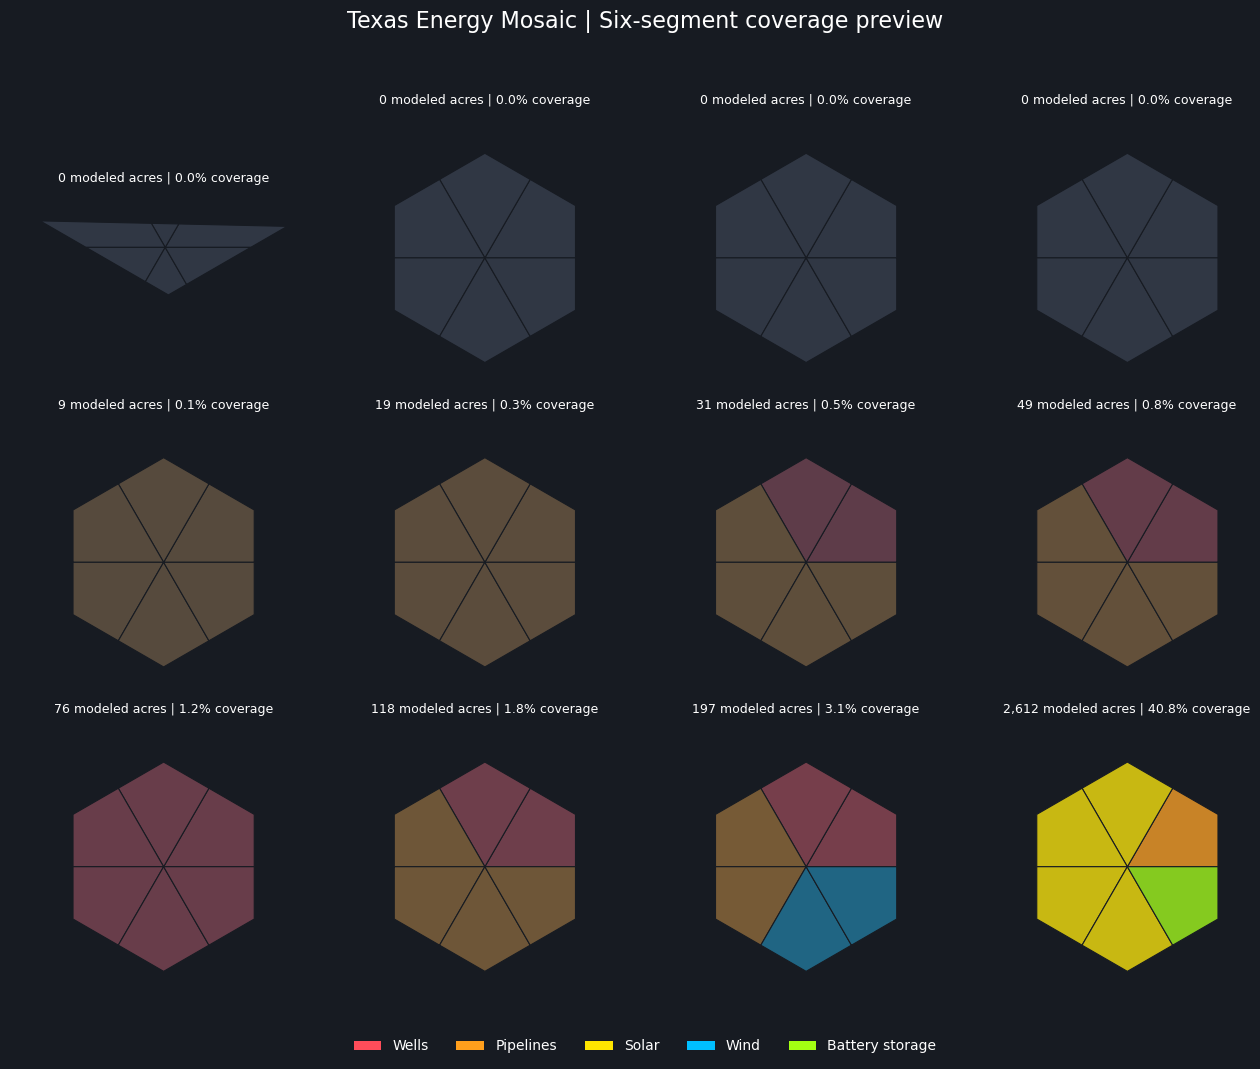

PREVIEW VALIDATION PASSED
Hexagons tested: 12
Segments per hexagon: 6
Infrastructure categories: 5
Source: final_mosaic


In [20]:
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

from shapely.geometry import Polygon
from shapely.ops import unary_union
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch

# I use my validated final mosaic and all five categories.
acreage_cols = [
    "well_acres",
    "pipeline_acres",
    "solar_acres",
    "wind_acres",
    "battery_acres"
]

segment_colors = {
    "well_acres": "#FF4D5A",
    "pipeline_acres": "#FF9F1C",
    "solar_acres": "#FFE600",
    "wind_acres": "#00BFFF",
    "battery_acres": "#A3FF12"
}

background_color = "#303744"
figure_background = "#171B22"

# I confirm that the required fields and geometries exist.
assert all(col in final_mosaic.columns for col in acreage_cols)
assert final_mosaic.crs is not None
assert final_mosaic.geometry.notna().all()
assert final_mosaic.geometry.is_valid.all()

# I work in the Texas projected coordinate system.
preview_data = final_mosaic.to_crs("EPSG:3083").copy()

# I calculate the modeled footprint in each hexagon.
preview_data["total_acres"] = (
    preview_data[acreage_cols].sum(axis=1)
)

# I select 12 representative hexagons across the
# distribution of modeled infrastructure acreage.
preview_data = preview_data.loc[
    ~preview_data.geometry.is_empty
].sort_values("total_acres")

assert len(preview_data) >= 12

positions = np.linspace(
    0,
    len(preview_data) - 1,
    12
).astype(int)

selected = preview_data.iloc[positions].copy()

# I blend the category colors with the background.
def blend_color(color, background, opacity):

    foreground = np.array(to_rgb(color))
    backdrop = np.array(to_rgb(background))

    return tuple(
        opacity * foreground
        + (1 - opacity) * backdrop
    )


# I allocate six segments using square-root weighting.
# I reserve one segment for every present category.
def allocate_segments(values, total_segments=6):

    values = np.asarray(values, dtype=float)

    assert np.isfinite(values).all()
    assert (values >= 0).all()

    counts = np.zeros(len(values), dtype=int)
    present = np.flatnonzero(values > 0)

    if len(present) == 0:
        return counts

    assert len(present) <= total_segments

    counts[present] = 1
    remaining = total_segments - len(present)

    if remaining > 0:

        weights = np.sqrt(values[present])
        exact = weights / weights.sum() * remaining

        additional = np.floor(exact).astype(int)
        counts[present] += additional

        leftover = remaining - additional.sum()

        fractions = exact - additional
        order = np.argsort(-fractions, kind="stable")

        for idx in order[:leftover]:
            counts[present[idx]] += 1

    assert counts.sum() == total_segments
    assert (counts[present] >= 1).all()

    return counts


# I construct six angular sectors and clip them
# to the actual geometry of each selected hexagon.
def create_six_segments(geometry):

    center = geometry.centroid

    xmin, ymin, xmax, ymax = geometry.bounds

    radius = max(
        np.hypot(x - center.x, y - center.y)
        for x in (xmin, xmax)
        for y in (ymin, ymax)
    ) * 2

    pieces = []

    for i in range(6):

        angle_1 = np.deg2rad(i * 60)
        angle_2 = np.deg2rad((i + 1) * 60)

        wedge = Polygon([
            (center.x, center.y),
            (
                center.x + radius * np.cos(angle_1),
                center.y + radius * np.sin(angle_1)
            ),
            (
                center.x + radius * np.cos(angle_2),
                center.y + radius * np.sin(angle_2)
            )
        ])

        pieces.append(geometry.intersection(wedge))

    # I verify that the segments reconstruct the
    # original hexagon without meaningful area loss.
    reconstructed = unary_union(pieces)

    assert np.isclose(
        reconstructed.area,
        geometry.area,
        rtol=1e-6,
        atol=0.01
    ), "Segment geometry does not reconstruct the hexagon."

    return pieces


# I draw the 12 selected hexagons.
fig, axes = plt.subplots(
    3, 4,
    figsize=(13, 11)
)

fig.patch.set_facecolor(figure_background)

for ax, (_, record) in zip(
    axes.flat,
    selected.iterrows()
):

    geometry = record.geometry

    values = np.array(
        [record[col] for col in acreage_cols],
        dtype=float
    )

    hex_acres = geometry.area / 4046.8564224

    total_coverage = (
        values.sum() / hex_acres
        if hex_acres > 0 else 0
    )

    counts = allocate_segments(values)

    assignments = []

    for column, count in zip(acreage_cols, counts):
        assignments.extend(
            [segment_colors[column]] * count
        )

    if not assignments:
        assignments = [background_color] * 6

    # I preserve the original nonlinear intensity method.
    intensity = min(
        1.0,
        max(0.0, total_coverage) ** 0.4
    )

    opacity = 0.12 + 0.88 * intensity

    # I generate six clipped sectors per hexagon.
    pieces = create_six_segments(geometry)

    for piece, color in zip(pieces, assignments):

        if piece.is_empty:
            continue

        display_color = blend_color(
            color,
            background_color,
            opacity
        )

        gpd.GeoSeries(
            [piece],
            crs=preview_data.crs
        ).plot(
            ax=ax,
            color=[display_color],
            edgecolor=figure_background,
            linewidth=0.8
        )

    xmin, ymin, xmax, ymax = geometry.bounds

    margin = max(
        xmax - xmin,
        ymax - ymin
    ) * 0.12

    ax.set_xlim(xmin - margin, xmax + margin)
    ax.set_ylim(ymin - margin, ymax + margin)

    ax.set_aspect("equal")
    ax.set_facecolor(figure_background)
    ax.axis("off")

    ax.set_title(
        f"{record['total_acres']:,.0f} modeled acres | "
        f"{total_coverage * 100:.1f}% coverage",
        color="white",
        fontsize=9
    )


# I display all five infrastructure categories separately.
legend_handles = [
    Patch(facecolor=segment_colors["well_acres"], label="Wells"),
    Patch(facecolor=segment_colors["pipeline_acres"], label="Pipelines"),
    Patch(facecolor=segment_colors["solar_acres"], label="Solar"),
    Patch(facecolor=segment_colors["wind_acres"], label="Wind"),
    Patch(facecolor=segment_colors["battery_acres"], label="Battery storage")
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    frameon=False,
    labelcolor="white",
    bbox_to_anchor=(0.5, 0.02)
)

fig.suptitle(
    "Texas Energy Mosaic | Six-segment coverage preview",
    color="white",
    fontsize=16
)

plt.tight_layout(rect=[0, 0.07, 1, 0.95])
plt.show()

print("PREVIEW VALIDATION PASSED")
print("Hexagons tested:", len(selected))
print("Segments per hexagon: 6")
print("Infrastructure categories: 5")
print("Source: final_mosaic")

In [21]:
#the first hexagon looks weird

In [22]:
# I prepare the statewide mosaic using my validated
# hexagon-level infrastructure acreage dataset.
#
# I preserve the original acreage values and calculate
# visualization properties separately.
#
# I treat the six segments as schematic representations,
# not actual infrastructure locations.

acreage_cols = [
    "well_acres",
    "pipeline_acres",
    "solar_acres",
    "wind_acres",
    "battery_acres"
]

statewide_mosaic = final_mosaic.copy()

# I verify the dataset before calculating visualization values.
assert statewide_mosaic.crs is not None
assert statewide_mosaic.crs.to_epsg() == 3083
assert statewide_mosaic["hex_id"].is_unique
assert len(statewide_mosaic) == 27421

assert statewide_mosaic.geometry.notna().all()
assert statewide_mosaic.geometry.is_valid.all()
assert (~statewide_mosaic.geometry.is_empty).all()

assert all(
    col in statewide_mosaic.columns
    for col in acreage_cols
)

assert statewide_mosaic[acreage_cols].notna().all().all()

assert (
    statewide_mosaic[acreage_cols] >= 0
).all().all(), "Negative modeled acreage detected."

# I calculate each hexagon's geographic area in acres.
statewide_mosaic["hex_area_acres"] = (
    statewide_mosaic.geometry.area / 4046.8564224
)

assert (
    statewide_mosaic["hex_area_acres"] > 0
).all(), "Invalid hexagon area detected."

# I calculate the combined modeled infrastructure acreage.
# I do not interpret this as unique physical land coverage.
statewide_mosaic["total_modeled_acres"] = (
    statewide_mosaic[acreage_cols].sum(axis=1)
)

statewide_mosaic["modeled_coverage_pct"] = (
    statewide_mosaic["total_modeled_acres"]
    / statewide_mosaic["hex_area_acres"]
    * 100
)

# I calculate display opacity using nonlinear scaling.
# I cap coverage at 100% for visualization only.
display_fraction = np.clip(
    statewide_mosaic["modeled_coverage_pct"] / 100,
    0,
    1
)

statewide_mosaic["display_opacity"] = (
    0.12 + 0.88 * display_fraction ** 0.4
)

# I allocate six segments using square-root weighting.
# I reserve one segment for every present category.
def assign_segments(row):

    values = np.array(
        [row[col] for col in acreage_cols],
        dtype=float
    )

    present = np.flatnonzero(values > 0)

    if len(present) == 0:
        return [None] * 6

    assert len(present) <= 6

    counts = np.zeros(len(values), dtype=int)
    counts[present] = 1

    remaining = 6 - len(present)

    # I distribute the remaining segments according
    # to the square-root-transformed acreage values.
    if remaining > 0:

        weights = np.sqrt(values[present])
        exact = weights / weights.sum() * remaining

        additional = np.floor(exact).astype(int)
        counts[present] += additional

        leftover = remaining - additional.sum()

        order = np.argsort(
            -(exact - additional),
            kind="stable"
        )

        for idx in order[:leftover]:
            counts[present[idx]] += 1

    assignments = []

    for column, count in zip(acreage_cols, counts):
        assignments.extend([column] * count)

    assert len(assignments) == 6
    assert all(
        assignments.count(acreage_cols[idx]) >= 1
        for idx in present
    )

    return assignments


# I assign six schematic segments to every hexagon.
statewide_mosaic["segments"] = (
    statewide_mosaic.apply(
        assign_segments,
        axis=1
    )
)

# I verify that every hexagon has exactly six assignments.
assert (
    statewide_mosaic["segments"]
    .apply(len)
    .eq(6)
    .all()
)

# I verify that every present category receives a segment.
for column in acreage_cols:

    missing_assignments = sum(
        value > 0 and column not in assignments
        for value, assignments in zip(
            statewide_mosaic[column],
            statewide_mosaic["segments"]
        )
    )

    assert missing_assignments == 0, (
        f"Missing segment assignments for {column}"
    )

# I verify that the original modeled acreage is unchanged.
for column in acreage_cols:

    assert np.isclose(
        statewide_mosaic[column].sum(),
        final_mosaic[column].sum(),
        atol=0.01,
        rtol=0
    ), f"Acreage changed for {column}"

# I identify hexagons whose summed modeled acreage
# exceeds their geographic area.
over_100 = (
    statewide_mosaic["modeled_coverage_pct"] > 100
).sum()

print("STATEWIDE MOSAIC VALIDATION")
print("=" * 55)

print(
    "Hexagons:",
    f"{len(statewide_mosaic):,}"
)

print(
    "Total segment assignments:",
    f"{len(statewide_mosaic) * 6:,}"
)

print(
    "Hexagons exceeding 100% modeled coverage:",
    f"{over_100:,}"
)

print("\nModeled coverage distribution (%):")

print(
    statewide_mosaic["modeled_coverage_pct"]
    .describe()
    .round(2)
)

print("\nModeled acreage by infrastructure category:")

print(
    statewide_mosaic[acreage_cols]
    .sum()
    .round(2)
)

print("\nSegment assignment validation passed.")

STATEWIDE MOSAIC VALIDATION
Hexagons: 27,421
Total segment assignments: 164,526
Hexagons exceeding 100% modeled coverage: 0

Modeled coverage distribution (%):
count    27421.00
mean         1.07
std          1.97
min          0.00
25%          0.00
50%          0.38
75%          1.33
max         40.81
Name: modeled_coverage_pct, dtype: float64

Modeled acreage by infrastructure category:
well_acres        657689.62
pipeline_acres    984144.19
solar_acres       143025.17
wind_acres         73168.42
battery_acres       1390.93
dtype: float64

Segment assignment validation passed.


In [23]:
import numpy as np
import geopandas as gpd
from matplotlib.colors import to_rgb, to_hex

# I load my previously validated segmented mosaic.
segment_path = (
    OUTPUT / "Texas_10sqmi_Segmented_Mosaic_Final.parquet"
)

segmented_mosaic = gpd.read_parquet(segment_path)

# I define the updated infrastructure colors.
segment_colors = {
    "well_acres": "#FF4D5A",
    "pipeline_acres": "#FF9F1C",
    "solar_acres": "#FFE600",
    "wind_acres": "#00BFFF",
    "battery_acres": "#A3FF12"
}

background_color = "#303744"

# I preserve the original coverage-dependent opacity.
def blend_color(foreground, background, opacity):
    foreground_rgb = np.array(to_rgb(foreground))
    background_rgb = np.array(to_rgb(background))

    return to_hex(
        foreground_rgb * opacity
        + background_rgb * (1 - opacity)
    )

# I update colors without rebuilding any sector geometries.
segmented_mosaic["display_color"] = [
    (
        background_color
        if category == "none"
        else blend_color(
            segment_colors[category],
            background_color,
            opacity
        )
    )
    for category, opacity in zip(
        segmented_mosaic["category"],
        segmented_mosaic["display_opacity"]
    )
]

# I verify that I have retained the original sectors.
assert len(segmented_mosaic) == 164495
assert segmented_mosaic["display_color"].notna().all()

# I save a separate recolored version to preserve the original.
recolored_path = (
    OUTPUT / "Texas_10sqmi_Segmented_Mosaic_Bold_Colors.parquet"
)

segmented_mosaic.to_parquet(recolored_path)

print("Recolored mosaic saved:", recolored_path)
print("Sectors:", f"{len(segmented_mosaic):,}")
print("Geometry reconstruction was not required.")

Recolored mosaic saved: G:\My Drive\Projects\Large projects\2026TexasEnergyFootprint\07_Visualization\03_Texas_Energy_Land_Mosaic\Final_Rebuilt\Texas_10sqmi_Segmented_Mosaic_Bold_Colors.parquet
Sectors: 164,495
Geometry reconstruction was not required.


In [24]:
import gc
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import folium

from pathlib import Path
from matplotlib.colors import to_rgba
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon as MplPolygon
from IPython.display import display, FileLink

# I use my validated final Texas energy mosaic.
PROJECT_ROOT = Path(
    r"G:\My Drive\Projects\Large projects\2026TexasEnergyFootprint"
)

OUTPUT = (
    PROJECT_ROOT
    / "07_Visualization"
    / "03_Texas_Energy_Land_Mosaic"
    / "Final_Rebuilt"
)

mosaic_path = OUTPUT / "Texas_Energy_Mosaic_Final.parquet"

assert mosaic_path.exists()

# I use my updated five-category color palette.
layer_styles = {
    "well": ("Oil and gas wells", "#A78BFA"),
    "pipeline": ("Pipelines", "#FF9F1C"),
    "solar": ("Solar", "#FFE600"),
    "wind": ("Wind", "#00BFFF"),
    "battery": ("Battery storage", "#A3FF12")
}

BACKGROUND = "#171B22"
GRID_EDGE = "#39414D"

# I reuse the existing validated raster layers.
grid_png = OUTPUT / "Texas_Grid_Background.png"
outline_png = OUTPUT / "Texas_State_Outline.png"

for path in [grid_png, outline_png]:
    assert path.exists(), f"Missing raster: {path}"

for category in ["pipeline", "solar", "wind", "battery"]:
    path = OUTPUT / f"Texas_{category}_Raster_Overlay_V2.png"
    assert path.exists(), f"Missing raster: {path}"

# I load and validate the final mosaic.
mosaic = gpd.read_parquet(mosaic_path)

assert len(mosaic) == 27421
assert mosaic["hex_id"].is_unique
assert mosaic.crs.to_epsg() == 3083

assert mosaic.geometry.notna().all()
assert (~mosaic.geometry.is_empty).all()
assert mosaic.geometry.is_valid.all()

assert np.isclose(
    mosaic["well_acres"].sum(),
    657689.62,
    atol=0.1,
    rtol=0
)

# I calculate hexagon areas before converting the CRS.
mosaic["hex_area_acres"] = (
    mosaic.geometry.area / 4046.8564224
)

assert mosaic["hex_area_acres"].gt(0).all()

mosaic = mosaic.to_crs("EPSG:4326")

xmin, ymin, xmax, ymax = mosaic.total_bounds

image_bounds = [
    [ymin, xmin],
    [ymax, xmax]
]

# I preserve the image dimensions used in my previous map.
IMAGE_WIDTH = 1800

IMAGE_HEIGHT = max(
    1,
    int(
        IMAGE_WIDTH
        * (ymax - ymin)
        / (xmax - xmin)
    )
)

# I preserve the coverage-dependent opacity method.
def coverage_opacity(modeled_pct):

    intensity = np.minimum(
        1.0,
        np.sqrt(np.maximum(0, modeled_pct) / 10.0)
    )

    return 0.35 + 0.60 * intensity


# I regenerate only the wells raster using purple.
print("Recoloring oil and gas wells...")

subset = mosaic.loc[
    mosaic["well_acres"] > 0
].copy()

modeled_pct = (
    subset["well_acres"].to_numpy()
    / subset["hex_area_acres"].to_numpy()
    * 100
)

opacity_values = coverage_opacity(modeled_pct)

fig = plt.figure(
    figsize=(
        IMAGE_WIDTH / 100,
        IMAGE_HEIGHT / 100
    ),
    dpi=100
)

ax = fig.add_axes([0, 0, 1, 1])

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("auto")
ax.axis("off")

fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

patches = []
facecolors = []

for geometry, opacity in zip(
    subset.geometry,
    opacity_values
):

    if geometry.geom_type == "Polygon":
        polygons = [geometry]

    elif geometry.geom_type == "MultiPolygon":
        polygons = list(geometry.geoms)

    else:
        continue

    for polygon in polygons:

        if polygon.is_empty:
            continue

        patches.append(
            MplPolygon(
                np.asarray(polygon.exterior.coords),
                closed=True
            )
        )

        facecolors.append(
            to_rgba(
                layer_styles["well"][1],
                alpha=float(opacity)
            )
        )

collection = PatchCollection(
    patches,
    facecolors=facecolors,
    edgecolors=GRID_EDGE,
    linewidth=0.06,
    antialiased=True
)

ax.add_collection(collection)

# I save the purple wells layer separately.
well_png = OUTPUT / "Texas_well_Raster_Overlay_Purple.png"

fig.savefig(
    well_png,
    dpi=100,
    transparent=True,
    pad_inches=0
)

plt.close(fig)

del patches, facecolors, collection, subset
gc.collect()

print("Saved:", well_png.name)

# I create the lightweight interactive map.
texas_map = folium.Map(
    location=[31.0, -99.0],
    zoom_start=6,
    tiles=None,
    control_scale=True,
    zoom_control=True,
    prefer_canvas=True
)

# I style the map background and layer controls.
texas_map.get_root().header.add_child(
    folium.Element("""
    <style>
    .leaflet-container {
        background: #171B22 !important;
    }

    .leaflet-control-layers {
        background: #252B34 !important;
        color: white !important;
        border: 1px solid #4B5563 !important;
        border-radius: 8px !important;
        padding: 8px !important;
        font-family: Arial, sans-serif !important;
        font-size: 13px !important;
    }

    .leaflet-control-layers label {
        color: white !important;
    }

    .leaflet-control-scale-line {
        background: #252B34 !important;
        color: white !important;
        border-color: white !important;
    }
    </style>
    """)
)

# I add the original hexagon background.
folium.raster_layers.ImageOverlay(
    image=str(grid_png),
    bounds=image_bounds,
    opacity=1,
    interactive=False,
    control=False
).add_to(texas_map)

# I add five independently selectable infrastructure layers.
for category, (label, color) in layer_styles.items():

    if category == "well":
        png_path = well_png

    else:
        png_path = (
            OUTPUT
            / f"Texas_{category}_Raster_Overlay_V2.png"
        )

    group = folium.FeatureGroup(
        name=label,
        show=(category == "well"),
        overlay=True,
        control=True
    )

    folium.raster_layers.ImageOverlay(
        image=str(png_path),
        bounds=image_bounds,
        opacity=1,
        interactive=False
    ).add_to(group)

    group.add_to(texas_map)

# I keep the Texas outline visible above the infrastructure.
folium.raster_layers.ImageOverlay(
    image=str(outline_png),
    bounds=image_bounds,
    opacity=1,
    interactive=False,
    control=False
).add_to(texas_map)

folium.LayerControl(
    collapsed=False,
    position="topright"
).add_to(texas_map)

# I create a compact legend using the updated colors.
legend_items = "".join(
    f"""
    <div style="
        display:flex;
        align-items:center;
        gap:9px;
        margin-bottom:8px;
    ">
        <span style="
            display:inline-block;
            width:13px;
            height:13px;
            background:{color};
            border-radius:2px;
            flex-shrink:0;
        "></span>
        <span>{label}</span>
    </div>
    """
    for label, color in layer_styles.values()
)

legend_html = f"""
<div style="
    position:fixed;
    top:105px;
    left:15px;
    z-index:9999;
    width:225px;
    background:#20252D;
    color:#FFFFFF;
    padding:15px;
    border:1px solid #4B5563;
    border-radius:8px;
    font-family:Arial,sans-serif;
    font-size:12px;
    line-height:1.45;
    box-shadow:0 3px 12px #0008;
">

<div style="
    font-size:16px;
    font-weight:bold;
    margin-bottom:6px;
">
Texas Energy Footprint
</div>

<div style="
    font-size:11px;
    color:#BFC7D2;
    margin-bottom:14px;
">
Modeled infrastructure by 10-square-mile hexagon
</div>

{legend_items}

<div style="
    border-top:1px solid #48515E;
    padding-top:10px;
    margin-top:10px;
    color:#D1D5DB;
    font-size:10px;
">
More intense colors indicate higher modeled footprint
relative to hexagon area.<br><br>
Infrastructure footprints are estimates,
not actual facility boundaries.
Categories may overlap.
</div>

</div>
"""

texas_map.get_root().html.add_child(
    folium.Element(legend_html)
)

# I fit the complete Texas grid within the map.
texas_map.fit_bounds(
    image_bounds,
    padding=(5, 5)
)

# I save a new version without overwriting the earlier maps.
output_map = (
    OUTPUT / "Texas_Energy_Map_Lightweight_V3_Purple.html"
)

texas_map.save(str(output_map))

print("\nFINAL TEXAS ENERGY MAP")
print("=" * 55)

print("Saved:", output_map)

print(
    "HTML size:",
    f"{output_map.stat().st_size / 1024**2:.2f} MB"
)

print("Infrastructure categories:", len(layer_styles))
print("Hexagons:", f"{len(mosaic):,}")

print("\nPurple wells map generated successfully.")

# I open the saved HTML separately to avoid Jupyter memory issues.
display(FileLink(str(output_map)))

Recoloring oil and gas wells...
Saved: Texas_well_Raster_Overlay_Purple.png

FINAL TEXAS ENERGY MAP
Saved: G:\My Drive\Projects\Large projects\2026TexasEnergyFootprint\07_Visualization\03_Texas_Energy_Land_Mosaic\Final_Rebuilt\Texas_Energy_Map_Lightweight_V3_Purple.html
HTML size: 6.05 MB
Infrastructure categories: 5
Hexagons: 27,421

Purple wells map generated successfully.


G:\My Drive\Projects\Large projects\2026TexasEnergyFootprint\07_Visualization\03_Texas_Energy_Land_Mosaic\Final_Rebuilt\Texas_Energy_Map_Lightweight_V3_Purple.html